<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 4 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 4: Non-Abelian Quantum Hall States**

Tong (TIFR, Cambridge) · Output: `figures/ch04/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Left (ν=5/2 LL) | **오류** | ν=7/2 구조 (이전 버전 오류) | ✓ 이미 수정됨: n=0↑, n=0↓, n=1↑(half), n=1↓(empty) = 5/2 |
| fig02 | Right (braid) | **오류** | 상단 끝점 색상 교환 (이전 버전 오류) | ✓ 이미 수정됨: top-left=BLUE(γ₁), top-right=GREEN(γ₂) |
| fig01 | Left (ν=5/2 LL) | **경고** | n=1↓ empty 레벨이 경계선만 있어 시각적으로 불명확 | open circles + 'empty' 텍스트 추가 |
| fig02 | Middle (GSD) | **경고** | `d*0.6` 라벨: d=1(Nv=2)에서 label_y=0.6 < 1 → log₂ 스케일 하단 아래로 나감 | d≤2: 막대 위쪽 YELLOW, d≥4: 막대 안쪽 white. `ylim(0.7,80)` 명시 |
| fig03 | Middle (fusion) | **경고** | 동일한 d*0.6 문제 (N=2: d=1) | 동일하게 수정 |
| fig04 | Left (RR series) | **경고** | axvline(0.5) 라벨 없음 | `ν=1/2 (CF sea)` 텍스트 추가 |
| fig02 | Right (braid) | **시인성** | 교차 지점에서 γ_1/γ_2 앞뒤 관계 불명확 | 교차 구간 BLUE 선을 끊어 γ_2가 앞임을 명시 |


## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Left (ν=5/2 LL) | **오류** | LL 채우기 다이어그램이 ν=7/2를 묘사: n=0(↑↓ full)+n=1↑(full)+n=1↓(half)=7/2 | 올바른 ν=5/2: n=0↑(full)+n=0↓(full)+n=1↑(half-filled, MR). LLL 완전히 채워진 후 2nd LL spin-up의 절반만 채움 |
| fig02 | Right (braid) | **오류** | 상단 끝점 색상·라벨 교환: γ₁(BLUE) 직선 경로는 상단 왼쪽(x=1)에서 끝나야 하는데 코드는 BLUE를 top-right에 배치 | top-left↔top-right 색상·라벨 수정 (γ₁ BLUE→top-left, γ₂ GREEN→top-right) |
| fig02 | Middle (GSD bar) | **경고** | `d*1.3` 라벨이 log 스케일 상단을 초과할 수 있음 (Nv=12: d=32, 라벨 위치 41.6) | 숫자를 막대 안쪽 중앙(white, bold)으로 이동 |
| fig03 | Middle (fusion space) | **경고** | 동일한 bar 라벨 문제 (`d*1.3`) | 동일하게 막대 안쪽 중앙으로 이동 |
| fig04 | Left (RR series) | **경고** | k=4,5 라벨이 `xlim=1.05` 밖으로 클리핑 | 라벨 단축 + `xlim→1.45`로 확장 |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`


---
## fig01 · Moore-Read State & ν=5/2 (§4.1–4.2)

**Left**: Landau level filling diagram showing $\nu=5/2$ structure  
**Middle**: Pair correlations — Laughlin vs Moore-Read (Pfaffian)  
**Right**: Moore-Read wavefunction structure and key properties

  saved -> figures/ch04/fig01_moore_read.png


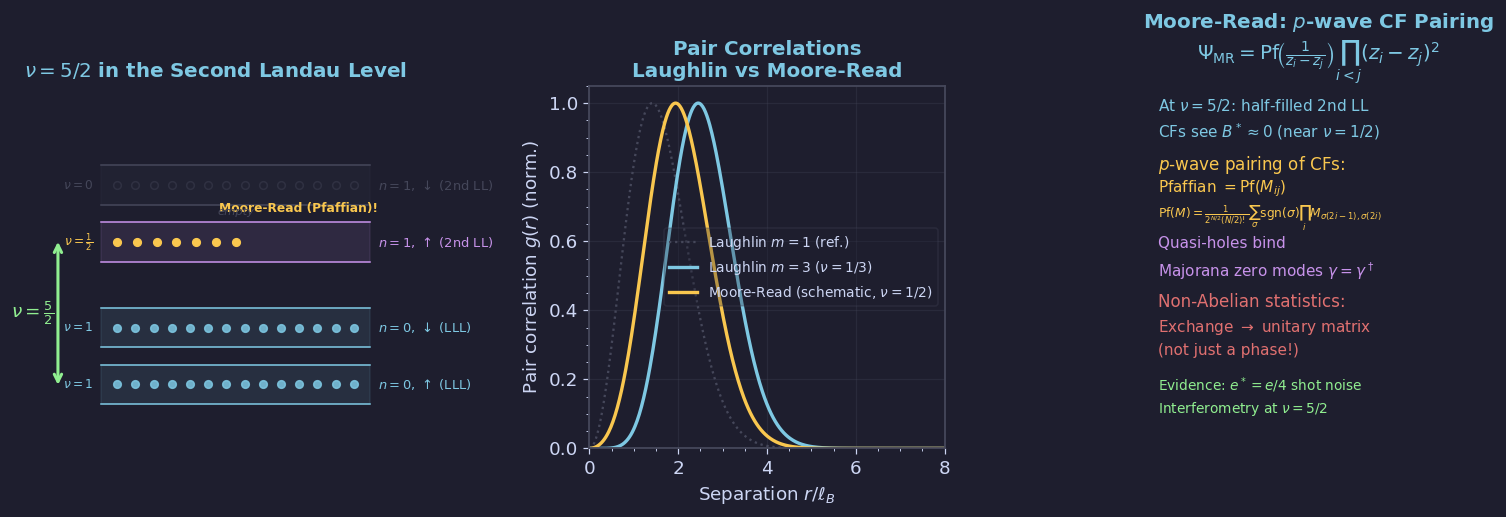

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · Moore-Read State & ν=5/2 ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Landau level filling diagram — ν=5/2 in second LL
ax = axes[0]
ax.set_xlim(-0.5, 4); ax.set_ylim(-0.1, 5.0); ax.axis('off')
ax.set_title(r'$\nu=5/2$ in the Second Landau Level', color=BLUE)

# Correct ν=5/2 structure (Zeeman-split picture):
#   n=0 ↑ (LLL spin-up):   fully filled  → ν=1
#   n=0 ↓ (LLL spin-down): fully filled  → ν=1  (total LLL: ν=2)
#   n=1 ↑ (2nd LL spin-up): HALF filled  → ν=1/2  ← Moore-Read lives here
#   n=1 ↓ (2nd LL spin-down): empty
# Total: 1+1+1/2 = 5/2 ✓
ll_labels  = ['$n=0$, $\\uparrow$ (LLL)',
              '$n=0$, $\\downarrow$ (LLL)',
              '$n=1$, $\\uparrow$ (2nd LL)',
              '$n=1$, $\\downarrow$ (2nd LL)']
ll_centers = [0.8, 1.6, 2.8, 3.6]
ll_colors  = [BLUE, BLUE, PURPLE, EDGE]
ll_fill    = [1.0, 1.0, 0.5, 0.0]   # fraction filled

for ll_y, ll_lab, ll_col in zip(ll_centers, ll_labels, ll_colors):
    ax.fill_between([0.3, 3.7], ll_y-0.28, ll_y+0.28, color=ll_col, alpha=0.10)
    ax.plot([0.3, 3.7], [ll_y-0.28, ll_y-0.28], color=ll_col, lw=1.0)
    ax.plot([0.3, 3.7], [ll_y+0.28, ll_y+0.28], color=ll_col, lw=1.0)
    ax.text(3.8, ll_y, ll_lab, va='center', color=ll_col, fontsize=8.5)

# n=0 ↑: fully filled
for xi in np.linspace(0.5, 3.5, 14):
    ax.plot(xi, ll_centers[0], 'o', color=BLUE, ms=5, alpha=0.85)
ax.text(0.2, ll_centers[0], r'$\nu=1$', va='center', color=BLUE, fontsize=8, ha='right')

# n=0 ↓: fully filled
for xi in np.linspace(0.5, 3.5, 14):
    ax.plot(xi, ll_centers[1], 'o', color=BLUE, ms=5, alpha=0.85)
ax.text(0.2, ll_centers[1], r'$\nu=1$', va='center', color=BLUE, fontsize=8, ha='right')

# n=1 ↑: HALF filled — Moore-Read
for xi in np.linspace(0.5, 2.0, 7):
    ax.plot(xi, ll_centers[2], 'o', color=YELLOW, ms=5)
ax.text(0.2, ll_centers[2], r'$\nu=\frac{1}{2}$', va='center', color=YELLOW,
        fontsize=8, ha='right', fontweight='bold')
ax.text(2.8, ll_centers[2]+0.42,
        r'Moore-Read (Pfaffian)!', ha='center',
        color=YELLOW, fontsize=8, fontweight='bold')

# n=1 ↓: empty — open circles to show unoccupied level
for xi in np.linspace(0.5, 3.5, 14):
    ax.plot(xi, ll_centers[3], 'o', color=EDGE, ms=5, alpha=0.4,
            markerfacecolor='none', markeredgecolor=EDGE, markeredgewidth=1.0)
ax.text(0.2, ll_centers[3], r'$\nu=0$', va='center', color=EDGE, fontsize=8, ha='right')
ax.text(2.0, ll_centers[3]-0.42, 'empty', ha='center', color=EDGE, fontsize=7.5, style='italic')

# Brace / arrow: total ν = 5/2
ax.annotate('', xy=(-0.25, ll_centers[2]+0.05), xytext=(-0.25, ll_centers[0]-0.05),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2.0))
ax.text(-0.30, (ll_centers[0]+ll_centers[2])/2,
        r'$\nu=\frac{5}{2}$', color=GREEN, fontsize=12,
        fontweight='bold', ha='right', va='center')

# Middle: Pfaffian vs Laughlin — pair correlation comparison
ax2 = axes[1]
r = np.linspace(0.001, 8, 500); ell=1.0
# Laughlin m=3: g(r) ~ r^6 * exp(-r^2/2)
g_L3 = r**6 * np.exp(-r**2/(2*ell**2)); g_L3 /= g_L3.max()
# Moore-Read m=2 times Pfaffian factor (schematic): extra short-range bunching
g_MR = (r**4 + 0.5*r**2) * np.exp(-r**2/(2*ell**2)); g_MR /= g_MR.max()
# Laughlin m=1 (boson reference)
g_L1 = r**2 * np.exp(-r**2/(2*ell**2)); g_L1 /= g_L1.max()
ax2.plot(r, g_L1, color=EDGE,   lw=1.5, ls=':', label=r'Laughlin $m=1$ (ref.)')
ax2.plot(r, g_L3, color=BLUE,   lw=2.2, label=r'Laughlin $m=3$ ($\nu=1/3$)')
ax2.plot(r, g_MR, color=YELLOW, lw=2.2, label=r'Moore-Read (schematic, $\nu=1/2$)')
ax2.set_xlabel(r'Separation $r/\ell_B$')
ax2.set_ylabel(r'Pair correlation $g(r)$ (norm.)')
ax2.set_title('Pair Correlations\nLaughlin vs Moore-Read', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 8); ax2.set_ylim(0, 1.05)

# Right: p-wave Cooper pairing of composite fermions
ax3 = axes[2]
ax3.set_xlim(-0.1, 1.1); ax3.set_ylim(-0.1, 1.1); ax3.axis('off')
ax3.set_title('Moore-Read: $p$-wave CF Pairing\n'+
              r'$\Psi_{\rm MR}={\rm Pf}\!\left(\frac{1}{z_i-z_j}\right)\prod_{i<j}(z_i-z_j)^2$',
              color=BLUE)
items = [
    (r'At $\nu=5/2$: half-filled 2nd LL', BLUE, 10),
    (r'CFs see $B^*\approx0$ (near $\nu=1/2$)', BLUE, 10),
    ('', FG, 8),
    (r'$p$-wave pairing of CFs:', YELLOW, 11),
    (r'Pfaffian $= {\rm Pf}(M_{ij})$', YELLOW, 10),
    (r'${\rm Pf}(M)=\frac{1}{2^{N/2}(N/2)!}\sum_\sigma{\rm sgn}(\sigma)\prod_i M_{\sigma(2i-1),\sigma(2i)}$',
     YELLOW, 8),
    ('', FG, 8),
    (r'Quasi-holes bind', PURPLE, 10),
    (r'Majorana zero modes $\gamma=\gamma^\dagger$', PURPLE, 10),
    ('', FG, 8),
    (r'Non-Abelian statistics:', RED, 11),
    (r'Exchange $\to$ unitary matrix', RED, 10),
    (r'(not just a phase!)', RED, 10),
    ('', FG, 8),
    (r'Evidence: $e^*=e/4$ shot noise', GREEN, 9),
    (r'Interferometry at $\nu=5/2$', GREEN, 9),
]
y0 = 0.97
for txt, col, fs in items:
    ax3.text(0.05, y0, txt, transform=ax3.transAxes,
             color=col, fontsize=fs, va='top')
    y0 -= 0.068 if txt else 0.022

plt.tight_layout(pad=1.5)
save('fig01_moore_read.png', fig)


---
## fig02 · Majorana Zero Modes & Braiding (§4.2)

**Left**: Majorana zero modes $\gamma=\gamma^\dagger$ bound to vortex cores  
**Middle**: Ground-state degeneracy $2^{n-1}$ for $2n$ vortices  
**Right**: Braid diagram — $\gamma_1\to\gamma_2$, $\gamma_2\to-\gamma_1$

  saved -> figures/ch04/fig02_majorana_braiding.png


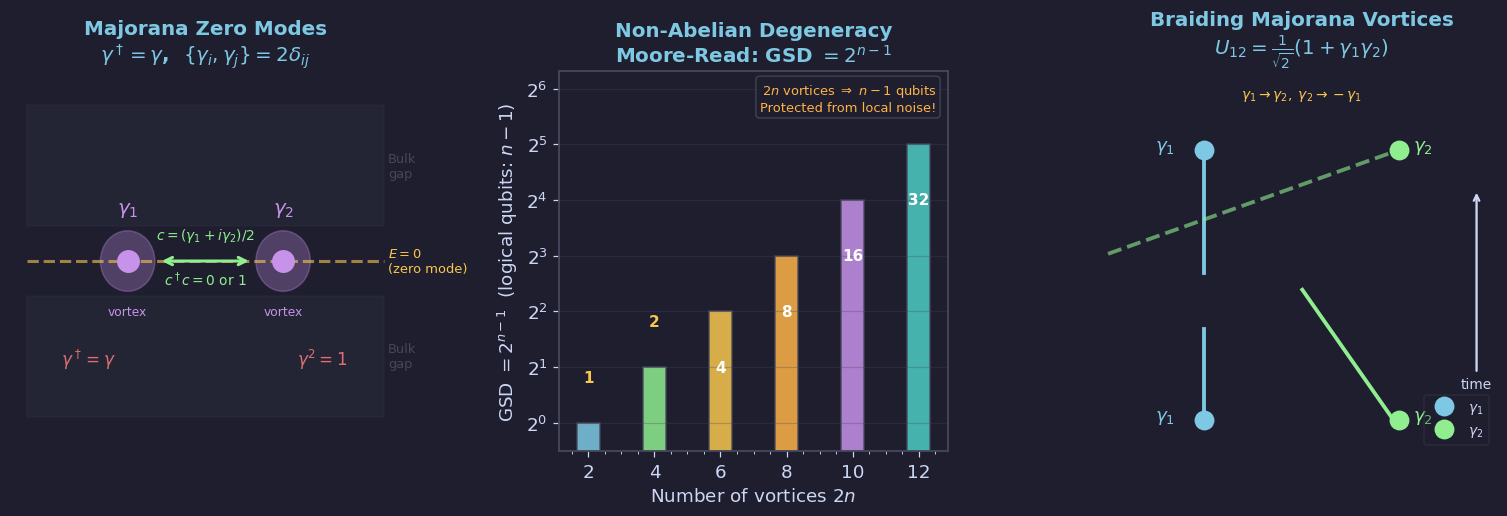

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · Majorana Zero Modes & Ground-State Degeneracy ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Majorana zero mode energy spectrum
ax = axes[0]
ax.set_xlim(-0.5, 4.5); ax.set_ylim(-2.2, 2.2); ax.axis('off')
ax.set_title('Majorana Zero Modes\n'+
             r'$\gamma^\dagger=\gamma$,  $\{\gamma_i,\gamma_j\}=2\delta_{ij}$', color=BLUE)
# Draw bulk gap
ax.fill_between([-0.3, 4.3], -1.8, -0.4, color=EDGE, alpha=0.15)
ax.fill_between([-0.3, 4.3],  0.4,  1.8, color=EDGE, alpha=0.15)
ax.text(4.35,  1.1, 'Bulk\ngap', va='center', color=EDGE, fontsize=8.5)
ax.text(4.35, -1.1, 'Bulk\ngap', va='center', color=EDGE, fontsize=8.5)
ax.plot([-0.3, 4.3], [0, 0], color=YELLOW, lw=2.0, ls='--', alpha=0.6)
ax.text(4.35, 0.0, '$E=0$\n(zero mode)', va='center', color=YELLOW, fontsize=8.5)
# Two vortex cores with Majorana modes
for vx, vy, lab in [(1.0, 0.0, r'$\gamma_1$'), (3.0, 0.0, r'$\gamma_2$')]:
    circ = plt.Circle((vx, vy), 0.35, color=PURPLE, alpha=0.3)
    ax.add_patch(circ)
    ax.plot(vx, vy, 'o', color=PURPLE, ms=14, zorder=5)
    ax.text(vx, vy+0.55, lab, ha='center', color=PURPLE, fontsize=13, fontweight='bold')
    ax.text(vx, -0.62, 'vortex', ha='center', color=PURPLE, fontsize=8)
# Complex fermion = pair of Majoranas
ax.annotate('', xy=(2.6, 0.0), xytext=(1.4, 0.0),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2.0))
ax.text(2.0, 0.25, r'$c=(\gamma_1+i\gamma_2)/2$', ha='center', color=GREEN, fontsize=9)
ax.text(2.0, -0.28, r'$c^\dagger c=0$ or $1$', ha='center', color=GREEN, fontsize=9)
# Self-conjugate property
ax.text(0.5, -1.2, r'$\gamma^\dagger=\gamma$', color=RED, fontsize=11, ha='center')
ax.text(3.5, -1.2, r'$\gamma^2=1$', color=RED, fontsize=11, ha='center')

# Middle: GSD vs number of vortices (2^{n-1})
ax2 = axes[1]
Nv = np.arange(2, 13, 2)
dim = 2**(Nv//2 - 1)
cols2 = [BLUE, GREEN, YELLOW, ORANGE, PURPLE, '#4ecdc4']
bars = ax2.bar(Nv, dim, color=cols2[:len(Nv)], alpha=0.85, edgecolor=EDGE, width=0.7)
ax2.set_yscale('log', base=2)
for n, d in zip(Nv, dim):
    if d <= 2:   # 막대가 너무 낮아 안쪽 표기 불가 → 위쪽에 컬러로
        ax2.text(n, d * 1.6, str(d), ha='center', va='bottom',
                 color=YELLOW, fontsize=10, fontweight='bold')
    else:         # 충분히 높은 막대 → 안쪽 중앙에 white로
        ax2.text(n, d * 0.5, str(d), ha='center', va='center',
                 color='white', fontsize=10, fontweight='bold')
ax2.set_xlabel('Number of vortices $2n$')
ax2.set_ylabel(r'GSD $= 2^{n-1}$  (logical qubits: $n-1$)')
ax2.set_title('Non-Abelian Degeneracy\n'+
              r'Moore-Read: GSD $= 2^{n-1}$', color=BLUE)
ax2.set_ylim(0.7, 80)   # log2 스케일: 최솟값 0.7로 d=1 막대 표시, 상단 80
ax2.grid(True, axis='y')
ax2.text(0.97, 0.97,
         r'$2n$ vortices $\Rightarrow$ $n-1$ qubits' + '\n' + r'Protected from local noise!',
         transform=ax2.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

# Right: Braiding unitary for two Majorana pairs
ax3 = axes[2]
ax3.set_xlim(0, 4); ax3.set_ylim(-0.3, 4.5); ax3.axis('off')
ax3.set_title('Braiding Majorana Vortices\n'+
              r'$U_{12}=\frac{1}{\sqrt{2}}(1+\gamma_1\gamma_2)$', color=BLUE)
t = np.linspace(0, 1, 150)

# Vortex 1: straight line x=1, y: 0→3.5
# 교차 구간(y≈1.3~1.9)에서 γ_2가 앞이므로 BLUE를 두 구간으로 분할
_y_full = np.linspace(0.1, 3.4, 500)
_cross_lo, _cross_hi = 1.25, 1.95   # γ_2 crossing y-range
_seg_lo = _y_full[_y_full <= _cross_lo]
_seg_hi = _y_full[_y_full >= _cross_hi]
ax3.plot(np.ones(len(_seg_lo))*1.0, _seg_lo, color=BLUE, lw=2.5)
ax3.plot(np.ones(len(_seg_hi))*1.0, _seg_hi, color=BLUE, lw=2.5)
# Vortex 2: over-crossing path
x2_lo = 3.0 - 2*t[:75]; y2_lo = 3.5*t[:75]
x2_hi = 1.0 + 2*(t[75:]-0.75)*4; y2_hi = 3.5*t[75:]
ax3.plot(x2_lo, y2_lo, color=GREEN, lw=2.5)          # in front
ax3.plot(x2_hi, y2_hi, color=GREEN, lw=2.5, ls='--', alpha=0.6)  # behind

ax3.plot(1.0, 0.1, 'o', color=BLUE,  ms=12, zorder=6, label=r'$\gamma_1$')
ax3.plot(3.0, 0.1, 'o', color=GREEN, ms=12, zorder=6, label=r'$\gamma_2$')
# γ_1(BLUE) 직선 x=1 → 상단 LEFT(1,3.5): BLUE
# γ_2(GREEN) 교차 x=3→1→3 → 상단 RIGHT(3,3.5): GREEN
ax3.plot(1.0, 3.5, 'o', color=BLUE,  ms=12, zorder=6)  # γ_1 ends top-left
ax3.plot(3.0, 3.5, 'o', color=GREEN, ms=12, zorder=6)  # γ_2 ends top-right
ax3.text(0.7, 0.1,  r'$\gamma_1$', color=BLUE,  fontsize=12, ha='right')
ax3.text(3.15, 0.1, r'$\gamma_2$', color=GREEN, fontsize=12)
ax3.text(0.7, 3.5,  r'$\gamma_1$', color=BLUE,  fontsize=12, ha='right')  # top-left
ax3.text(3.15, 3.5, r'$\gamma_2$', color=GREEN, fontsize=12)               # top-right
ax3.annotate('time', xy=(3.8, 3.0), xytext=(3.8, 0.5),
             arrowprops=dict(arrowstyle='->', color=FG, lw=1.5),
             color=FG, fontsize=9, ha='center')
ax3.text(2.0, 4.15,
         r'$\gamma_1\to\gamma_2,\;\gamma_2\to-\gamma_1$',
         ha='center', color=YELLOW, fontsize=9)
ax3.legend(fontsize=9, labelcolor=FG, loc='lower right')

plt.tight_layout(pad=1.5)
save('fig02_majorana_braiding.png', fig)


---
## fig03 · Non-Abelian Fusion Rules & Consistency (§4.3)

**Left**: Ising anyon model — fusion rules, conformal dims, quantum dimensions  
**Middle**: Fusion space dimension $2^{n-1}$ for $2n$ $\sigma$ anyons  
**Right**: $F$- and $R$-matrices, pentagon/hexagon equations, TQC potential

  saved -> figures/ch04/fig03_nonabelian_fusion.png


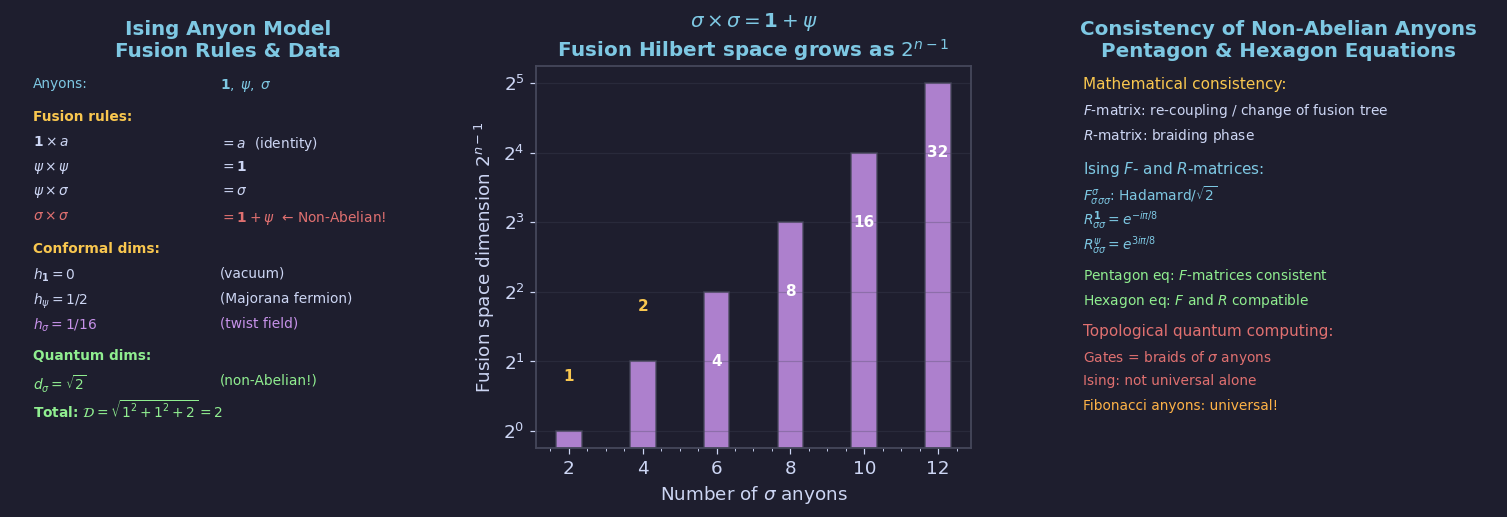

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · Non-Abelian Anyons: Fusion & Braiding ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Ising anyon fusion rules as a table
ax = axes[0]
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
ax.set_title('Ising Anyon Model\nFusion Rules & Data', color=BLUE)
rows = [
    ('Anyons:', r'$\mathbf{1},\;\psi,\;\sigma$', BLUE),
    ('', '', FG),
    ('Fusion rules:', '', YELLOW),
    (r'$\mathbf{1}\times a$', r'$= a$  (identity)', FG),
    (r'$\psi\times\psi$',     r'$= \mathbf{1}$', FG),
    (r'$\psi\times\sigma$',   r'$= \sigma$', FG),
    (r'$\sigma\times\sigma$', r'$= \mathbf{1}+\psi$  ← Non-Abelian!', RED),
    ('', '', FG),
    ('Conformal dims:', '', YELLOW),
    (r'$h_{\mathbf{1}}=0$',  r'(vacuum)',              FG),
    (r'$h_\psi=1/2$',        r'(Majorana fermion)',    FG),
    (r'$h_\sigma=1/16$',     r'(twist field)',         PURPLE),
    ('', '', FG),
    ('Quantum dims:', '', GREEN),
    (r'$d_\sigma=\sqrt{2}$', r'(non-Abelian!)',        GREEN),
    (r'Total: $\mathcal{D}=\sqrt{1^2+1^2+2}=2$', '',  GREEN),
]
y0 = 0.97
for lab, val, col in rows:
    if lab:
        ax.text(0.05, y0, lab, transform=ax.transAxes,
                color=col, fontsize=9, va='top', fontweight='bold' if val=='' else 'normal')
    if val:
        ax.text(0.48, y0, val, transform=ax.transAxes,
                color=col, fontsize=9, va='top')
    y0 -= 0.065 if lab or val else 0.02

# Middle: Fusion space dimension vs number of sigma anyons
ax2 = axes[1]
N_sigma = np.arange(2, 13, 2)
# For 2n sigma anyons: fusion space dim = 2^{n-1}
dim_sigma = 2**(N_sigma//2 - 1)
ax2.bar(N_sigma, dim_sigma, color=PURPLE, alpha=0.85, edgecolor=EDGE, width=0.7)
ax2.set_yscale('log', base=2)
for n, d in zip(N_sigma, dim_sigma):
    if d <= 2:   # 막대 낮음 → 위쪽에 컬러로
        ax2.text(n, d * 1.6, str(d), ha='center', va='bottom',
                 color=YELLOW, fontsize=10, fontweight='bold')
    else:         # 안쪽 중앙에 white로
        ax2.text(n, d * 0.5, str(d), ha='center', va='center',
                 color='white', fontsize=10, fontweight='bold')
ax2.set_xlabel(r'Number of $\sigma$ anyons')
ax2.set_ylabel(r'Fusion space dimension $2^{n-1}$')
ax2.set_title(r'$\sigma\times\sigma=\mathbf{1}+\psi$'+'\n'+
              r'Fusion Hilbert space grows as $2^{n-1}$', color=BLUE)
ax2.grid(True, axis='y')

# Right: Pentagon equation / F-matrix consistency (schematic)
ax3 = axes[2]
ax3.set_xlim(0, 1); ax3.set_ylim(0, 1); ax3.axis('off')
ax3.set_title('Consistency of Non-Abelian Anyons\nPentagon & Hexagon Equations', color=BLUE)
items = [
    ('Mathematical consistency:', YELLOW, 10),
    (r'$F$-matrix: re-coupling / change of fusion tree', FG, 9),
    (r'$R$-matrix: braiding phase', FG, 9),
    ('', FG, 8),
    ('Ising $F$- and $R$-matrices:', BLUE, 10),
    (r'$F^\sigma_{\sigma\sigma\sigma}$: Hadamard/$\sqrt{2}$',
     BLUE, 9),
    (r'$R^{\mathbf{1}}_{\sigma\sigma}=e^{-i\pi/8}$', BLUE, 9),
    (r'$R^{\psi}_{\sigma\sigma}=e^{3i\pi/8}$', BLUE, 9),
    ('', FG, 8),
    ('Pentagon eq: $F$-matrices consistent', GREEN, 9),
    ('Hexagon eq: $F$ and $R$ compatible', GREEN, 9),
    ('', FG, 8),
    ('Topological quantum computing:', RED, 10),
    (r'Gates = braids of $\sigma$ anyons', RED, 9),
    (r'Ising: not universal alone', RED, 9),
    (r'Fibonacci anyons: universal!', ORANGE, 9),
]
y0 = 0.97
for txt, col, fs in items:
    ax3.text(0.05, y0, txt, transform=ax3.transAxes,
             color=col, fontsize=fs, va='top')
    y0 -= 0.065 if txt else 0.02

plt.tight_layout(pad=1.5)
save('fig03_nonabelian_fusion.png', fig)


---
## fig04 · Read-Rezayi States & Topological Quantum Computing (§4.4)

**Left**: Read-Rezayi series $\nu=k/(k+2)$ — $\mathbb{Z}_k$ parafermion states  
**Middle**: TQC error suppression — topological vs conventional qubits  
**Right**: Summary table — non-Abelian anyon types and universality

  saved -> figures/ch04/fig04_tqc_rr_states.png


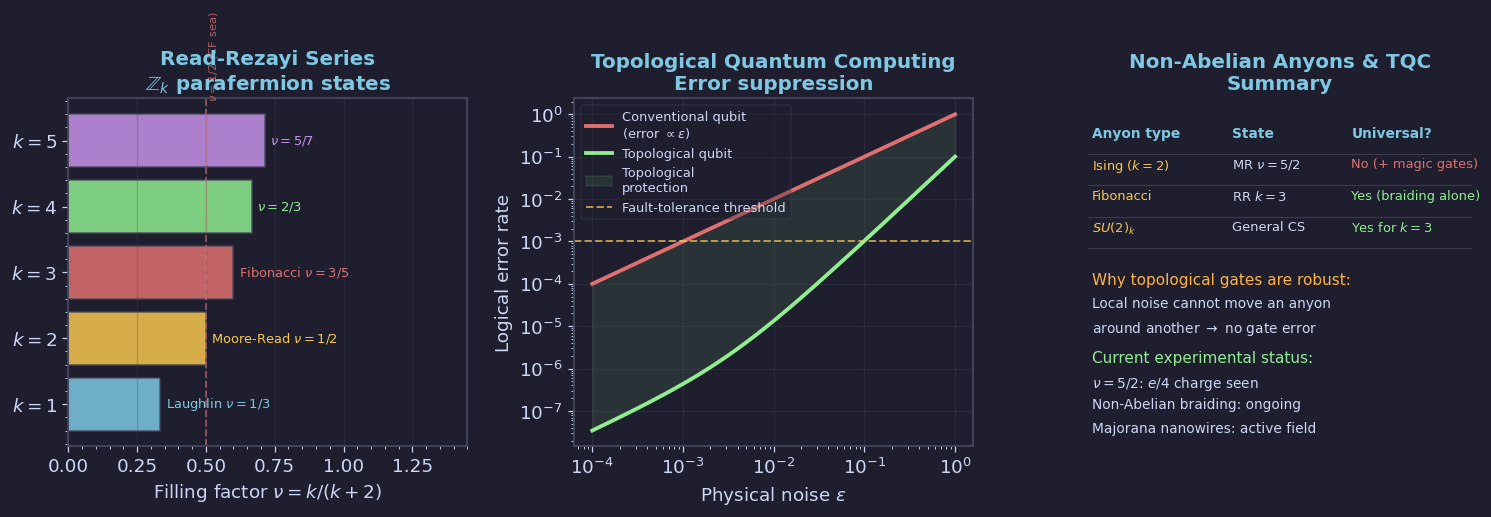

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Read-Rezayi States & Topological Quantum Computing ───────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Read-Rezayi series nu = k/(k+2) and their anyon types
ax = axes[0]
k_vals = [1, 2, 3, 4, 5]
nu_rr  = [k/(k+2) for k in k_vals]
labels = [r'$k=1$: Laughlin $\nu=1/3$',
          r'$k=2$: Moore-Read $\nu=1/2$',
          r'$k=3$: Fibonacci $\nu=3/5$',
          r'$k=4$: $\nu=2/3$',
          r'$k=5$: $\nu=5/7$']
cols_rr = [BLUE, YELLOW, RED, GREEN, PURPLE]
bars_rr = ax.barh(np.arange(len(k_vals)), nu_rr,
                  color=cols_rr, alpha=0.85, edgecolor=EDGE)
ax.set_yticks(np.arange(len(k_vals)))
ax.set_yticklabels([f'$k={k}$' for k in k_vals])
ax.set_xlabel(r'Filling factor $\nu = k/(k+2)$')
ax.set_title('Read-Rezayi Series\n'+
             r'$\mathbb{Z}_k$ parafermion states', color=BLUE)
# 라벨: bar 끝에서 오른쪽 여백에 표기; xlim 확장으로 클리핑 방지
short_labels = [r'Laughlin $\nu=1/3$',
                r'Moore-Read $\nu=1/2$',
                r'Fibonacci $\nu=3/5$',
                r'$\nu=2/3$',
                r'$\nu=5/7$']
for j, (bar, nu_f, lab) in enumerate(zip(bars_rr, nu_rr, short_labels)):
    ax.text(nu_f + 0.02, j, lab, va='center', color=cols_rr[j], fontsize=8.5)
ax.set_xlim(0, 1.45); ax.grid(True, axis='x')
ax.axvline(0.5, color=RED, lw=1.2, ls='--', alpha=0.6)
ax.text(0.505, 4.6, r'$\nu=1/2$'+' (CF sea)', color=RED,
        fontsize=7.5, va='bottom', rotation=90, alpha=0.8)

# Middle: TQC gate fidelity vs noise — topological vs conventional
ax2 = axes[1]
noise = np.logspace(-4, 0, 200)
# Conventional: error rate ~ epsilon (linear)
err_conv = noise
# Topological: error rate ~ exp(-L/xi) * epsilon (exponentially suppressed)
L_over_xi = 8
err_topo = noise * np.exp(-L_over_xi) + noise**2 * 1e-1
ax2.loglog(noise, err_conv, color=RED,    lw=2.5, label='Conventional qubit\n(error $\\propto \\epsilon$)')
ax2.loglog(noise, err_topo, color=GREEN,  lw=2.5, label=r'Topological qubit')
ax2.fill_between(noise, err_topo, err_conv, color=GREEN, alpha=0.1,
                 label='Topological\nprotection')
ax2.axhline(1e-3, color=YELLOW, lw=1.3, ls='--', alpha=0.7, label='Fault-tolerance threshold')
ax2.set_xlabel(r'Physical noise $\epsilon$')
ax2.set_ylabel('Logical error rate')
ax2.set_title('Topological Quantum Computing\nError suppression', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper left')
ax2.grid(True)

# Right: Summary — non-Abelian anyon types and TQC potential
ax3 = axes[2]
ax3.set_xlim(0,1); ax3.set_ylim(0,1); ax3.axis('off')
ax3.set_title('Non-Abelian Anyons & TQC\nSummary', color=BLUE)
table = [
    ['Anyon type',     'State',      'Universal?'],
    ['Ising ($k=2$)',  r'MR $\nu=5/2$', 'No (+ magic gates)'],
    ['Fibonacci',      r'RR $k=3$',     'Yes (braiding alone)'],
    [r'$SU(2)_k$',    'General CS',    r'Yes for $k=3$'],
]
col_x = [0.03, 0.38, 0.68]
col_w = [0.35, 0.30, 0.32]
y0 = 0.92
for ri, row in enumerate(table):
    for ci, (cell, cx) in enumerate(zip(row, col_x)):
        col = BLUE if ri==0 else (YELLOW if ci==0 else
                                  (GREEN if 'Yes' in cell else
                                   (RED if 'No' in cell else FG)))
        ax3.text(cx, y0, cell, transform=ax3.transAxes,
                 color=col, fontsize=8.5 if ri>0 else 9,
                 fontweight='bold' if ri==0 else 'normal', va='top')
    y0 -= 0.09
    ax3.plot([0.02, 0.98], [y0+0.01, y0+0.01], color=EDGE, lw=0.5,
             transform=ax3.transAxes, clip_on=False)

extra = [
    ('', FG, 8),
    ('Why topological gates are robust:', ORANGE, 10),
    (r'Local noise cannot move an anyon', FG, 9),
    (r'around another $\to$ no gate error', FG, 9),
    ('', FG, 8),
    ('Current experimental status:', GREEN, 10),
    (r'$\nu=5/2$: $e/4$ charge seen', FG, 9),
    (r'Non-Abelian braiding: ongoing', FG, 9),
    (r'Majorana nanowires: active field', FG, 9),
]
y_e = y0 - 0.04
for txt, col, fs in extra:
    ax3.text(0.03, y_e, txt, transform=ax3.transAxes,
             color=col, fontsize=fs, va='top')
    y_e -= 0.068 if txt else 0.02

plt.tight_layout(pad=1.5)
save('fig04_tqc_rr_states.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch04_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch04')):
        fpath = os.path.join('figures/ch04', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_moore_read.png
  added fig02_majorana_braiding.png
  added fig03_nonabelian_fusion.png
  added fig04_tqc_rr_states.png

Created: qhe_ch04_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>